In [1]:
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_openml
#boston = load_boston()
boston = fetch_openml(name="boston", version=1, as_frame = True)
print(boston.keys())

dict_keys(['data', 'target', 'frame', 'categories', 'feature_names', 'target_names', 'DESCR', 'details', 'url'])


In [12]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_squared_error, r2_score, root_mean_squared_error
from sklearn.preprocessing import StandardScaler

Regression models do not explicitly require feature scaling but it can improve it's performance in some aspects such as when regularizing the models.

In [5]:
SEED = 42
X = boston.data
y = boston.target
#splitting the data set to test and train
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state= SEED)

In [10]:
#using standard feature scaling , as mentioned in Geeks for geeks
scale = StandardScaler()
X_train_scaled = scale.fit_transform(X_train)
X_test_scaled = scale.transform(X_test)

In [20]:
#lAsso Model 
alpha_lasso = 0.1
model_lasso = Lasso(alpha)
model_lasso.fit(X_train_scaled, y_train)

y_train_pred_lasso = model_lasso.predict(X_train_scaled)
y_test_pred_lasso = model_lasso.predict(X_test_scaled)

train_mse_lasso = mean_squared_error(y_train, y_train_pred_lasso)
test_mse_lasso = mean_squared_error(y_test, y_test_pred_lasso)
rSq_lasso = r2_score(y_test, y_test_pred_lasso)

print("Used Alpha for Lasso Model: ", alpha_lasso)
print("Training MSE in Lasso Model : ", train_mse_lasso)
print("Testing MSE In Lasso Model: ", test_mse_lasso)
print("R^2 Score for Lasso Model: ", rSq_lasso)

Used Alpha for Lasso Model:  0.1
Training MSE in Lasso Model :  22.14949678237027
Testing MSE In Lasso Model:  25.65673936716768
R^2 Score for Lasso Model:  0.6501375183238987


In [18]:
#Ridge model for Boston data
alpha = 0.1
model_ridge = Ridge(alpha)
model_ridge.fit(X_train_scaled, y_train)

y_train_pred_ridge = model_ridge.predict(X_train_scaled)
y_test_pred_ridge = model_ridge.predict(X_test_scaled)

train_mse_ridge = mean_squared_error(y_train, y_train_pred_ridge)
test_mse_ridge = mean_squared_error(y_test, y_test_pred_ridge)
rSq_ridge = r2_score(y_test, y_test_pred_ridge)

print("Used Alpha for Ridge Model: ", alpha)
print("Training MSE in Ridge Model : ", train_mse_ridge)
print("Testing MSE In Ridge Model: ", test_mse_ridge)
print("R^2 Score for Ridge Model: ", rSq_ridge)

Used Alpha for Ridge Model:  0.1
Training MSE in Ridge Model :  21.641426807746587
Testing MSE In Ridge Model:  24.293294309665942
R^2 Score for Ridge Model:  0.6687298368808312


In [24]:
#Elastic model for boston housing data 
alpha_elastic = 0.1
l1_ratio = 0.5 #gamma in the ppt

model_elastic = ElasticNet(alpha= alpha_elastic, l1_ratio=l1_ratio)
model_elastic.fit(X_train_scaled, y_train)

y_train_pred_elastic = model_elastic.predict(X_train_scaled)
y_test_pred_elastic = model_elastic.predict(X_test_scaled)

train_mse_elastic = mean_squared_error(y_train, y_train_pred_elastic)
test_mse_elastic = mean_squared_error(y_test, y_test_pred_elastic)
rSq_elastic = r2_score(y_test, y_test_pred_elastic)

print("Used Alpha for Elastic Model: ", alpha_elastic)
print("Used l1 Ratio for Elastic Model: ", l1_ratio)

print("Training MSE in Elastic Model : ", train_mse_elastic)
print("Testing MSE In Elastic Model: ", test_mse_elastic)
print("R^2 Score for Elastic Model: ", rSq_elastic)

Used Alpha for Elastic Model:  0.1
Used l1 Ratio for Elastic Model:  0.5
Training MSE in Elastic Model :  22.181599033861165
Testing MSE In Elastic Model:  25.203552956840426
R^2 Score for Elastic Model:  0.6563172951034014


In [26]:
#comparing 3 
comparison = pd.DataFrame({"Model": ["Ridge", "Lasso", "Elastic Net"],
    "Training MSE": [
        train_mse_ridge,
        train_mse_lasso,
        train_mse_elastic
    ],
    "Testing MSE": [
        test_mse_ridge,
        test_mse_lasso,
        test_mse_elastic
    ],
    "R2 Score": [
        rSq_ridge,
        rSq_lasso,
        rSq_elastic
    ]
})

print(comparison)

         Model  Training MSE  Testing MSE  R2 Score
0        Ridge     21.641427    24.293294  0.668730
1        Lasso     22.149497    25.656739  0.650138
2  Elastic Net     22.181599    25.203553  0.656317


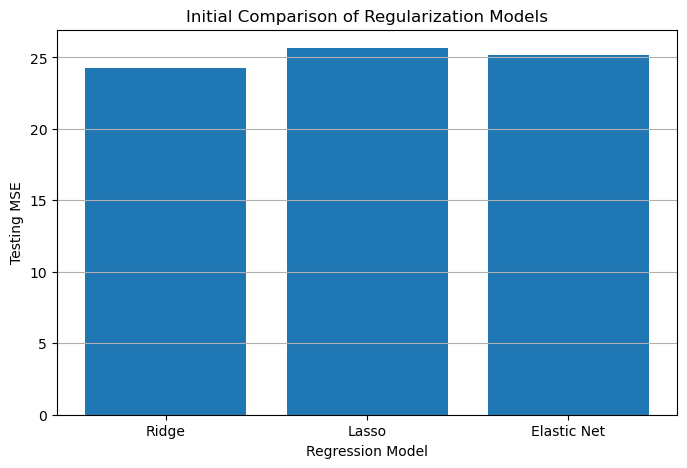

In [28]:
plt.figure(figsize=(8, 5))
plt.bar(comparison["Model"], comparison["Testing MSE"])
plt.xlabel("Regression Model")
plt.ylabel("Testing MSE")
plt.title("Initial Comparison of Regularization Models")
plt.grid(axis="y")
plt.show()

In [34]:
#Ridge - hyper paramater Tuning alpha
alpha_val = [0.01, 0.02, 0.05,0.1, 0.11, 0.5, 0.9, 1, 2]
ridge_results = []
for alpha in alpha_val:
    model_ridge = Ridge(alpha)
    model_ridge.fit(X_train_scaled, y_train)
    #predicting
    y_train_pred_ridge = model_ridge.predict(X_train_scaled)
    y_test_pred_ridge = model_ridge.predict(X_test_scaled)
    y_train_pred_ridge = model_ridge.predict(X_train_scaled)


    train_mse_ridge = mean_squared_error(y_train, y_train_pred_ridge)
    test_mse_ridge = mean_squared_error(y_test, y_test_pred_ridge)
    rSq_ridge = r2_score(y_test, y_test_pred_ridge)

    ridge_results.append([alpha, train_mse_ridge, test_mse_ridge,  rSq_ridge])

    

In [36]:
ridge_df = pd.DataFrame(ridge_results, columns=["Alpha", "Training MSE", "Testing MSE", "R2 Score"])
print(ridge_df)

   Alpha  Training MSE  Testing MSE  R2 Score
0   0.01     21.641413    24.291337  0.668757
1   0.02     21.641413    24.291554  0.668754
2   0.05     21.641416    24.292207  0.668745
3   0.10     21.641427    24.293294  0.668730
4   0.11     21.641430    24.293512  0.668727
5   0.50     21.641756    24.302005  0.668611
6   0.90     21.642502    24.310724  0.668492
7   1.00     21.642751    24.312904  0.668462
8   2.00     21.646491    24.334650  0.668166


In [42]:
#best alpha is when testing MSE is lowest to prevent overfit (overfitted data doesnt perform well in testing data )
best_alpha_ridge = ridge_df.loc[ridge_df["Testing MSE"].idxmin()]
print("Best Alpha in the Ridge Model: ", best_alpha_ridge["Alpha"])
print("Minimum Testing MSE in Ridge Model: ", best_alpha_ridge["Testing MSE"])
print("R2 Score for Best Ridge Model: ",  best_alpha_ridge["R2 Score"])

Best Alpha in the Ridge Model:  0.01
Minimum Testing MSE in Ridge Model:  24.291336890171532
R2 Score for Best Ridge Model:  0.6687565288011175


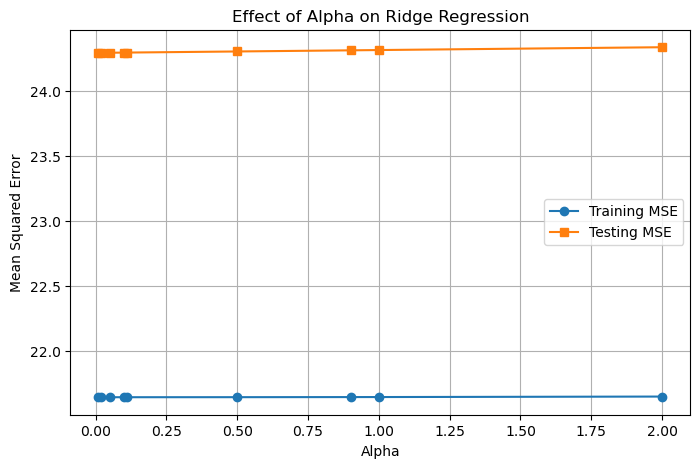

In [46]:
plt.figure(figsize=(8, 5))
plt.plot(ridge_df["Alpha"], ridge_df["Training MSE"], marker="o", label="Training MSE")
plt.plot(ridge_df["Alpha"], ridge_df["Testing MSE"], marker="s", label="Testing MSE")
plt.xlabel("Alpha")
plt.ylabel("Mean Squared Error")
plt.title("Effect of Alpha on Ridge Regression")
plt.legend()
plt.grid()
plt.show()

In [50]:
lasso_results = []
for alpha in alpha_val:
    model_lasso = Lasso(alpha)
    model_lasso.fit(X_train_scaled, y_train)
    #predicting
    y_train_pred_lasso = model_lasso.predict(X_train_scaled)
    y_test_pred_lasso = model_lasso.predict(X_test_scaled)
    y_train_pred_lasso = model_lasso.predict(X_train_scaled)


    train_mse_lasso = mean_squared_error(y_train, y_train_pred_lasso)
    test_mse_lasso = mean_squared_error(y_test, y_test_pred_lasso)
    rSq_lasso = r2_score(y_test, y_test_pred_lasso)

    lasso_results.append([alpha, train_mse_lasso, test_mse_lasso,  rSq_lasso])

In [52]:
lasso_df = pd.DataFrame(lasso_results, columns=["Alpha", "Training MSE", "Testing MSE", "R2 Score"])
print(lasso_df)

   Alpha  Training MSE  Testing MSE  R2 Score
0   0.01     21.648543    24.333499  0.668182
1   0.02     21.669830    24.394265  0.667353
2   0.05     21.784804    24.732823  0.662736
3   0.10     22.149497    25.656739  0.650138
4   0.11     22.249554    25.888787  0.646973
5   0.50     25.174336    27.313673  0.627543
6   0.90     27.423980    27.447554  0.625717
7   1.00     27.994144    27.577692  0.623943
8   2.00     33.703513    30.569830  0.583141


In [54]:
#its clear alpha =0.01 is the best for the both ridge and lasso models now in elastic we should only choose appropirate L1 values
#best alpha is when testing MSE is lowest to prevent overfit (overfitted data doesnt perform well in testing data )
best_alpha_lasso = lasso_df.loc[lasso_df["Testing MSE"].idxmin()]
print("Best Alpha in the Lasso Model: ", best_alpha_lasso["Alpha"])
print("Minimum Testing MSE in Lasso Model: ", best_alpha_lasso["Testing MSE"])
print("R2 Score for Best Lasso Model: ",  best_alpha_lasso["R2 Score"])

Best Alpha in the Lasso Model:  0.01
Minimum Testing MSE in Lasso Model:  24.333499160616338
R2 Score for Best Lasso Model:  0.6681815922762606


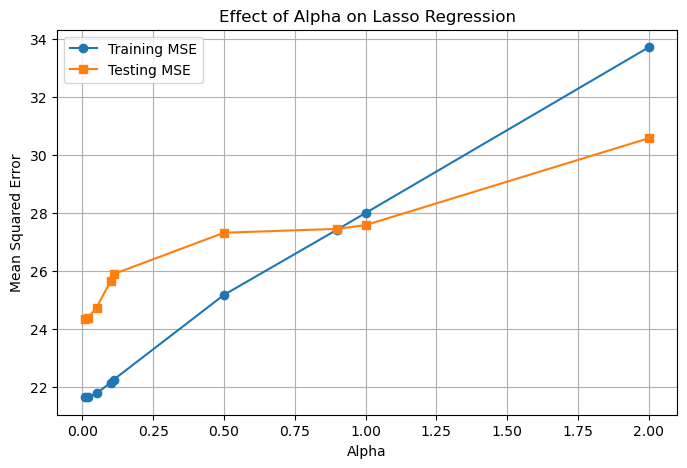

In [56]:
plt.figure(figsize=(8, 5))
plt.plot(lasso_df["Alpha"], lasso_df["Training MSE"], marker="o", label="Training MSE")
plt.plot(lasso_df["Alpha"], lasso_df["Testing MSE"], marker="s", label="Testing MSE")
plt.xlabel("Alpha")
plt.ylabel("Mean Squared Error")
plt.title("Effect of Alpha on Lasso Regression")
plt.legend()
plt.grid()
plt.show()

In [64]:
alpha_elastic = 0.1
l1_ratios = [0.01, 0.1, 0.5, 0.7, 1]
elastic_results = []

for ratio in l1_ratios:
    # 1. Corrected parameter name from 'ratio' to 'l1_ratio'
    model_elastic = ElasticNet(alpha=alpha_elastic, l1_ratio=ratio)
    model_elastic.fit(X_train_scaled, y_train)
    
    # 2. Removed the duplicate training prediction line
    y_train_pred_elastic = model_elastic.predict(X_train_scaled)
    y_test_pred_elastic = model_elastic.predict(X_test_scaled)
    
    # Metrics
    train_mse_elastic = mean_squared_error(y_train, y_train_pred_elastic)
    test_mse_elastic = mean_squared_error(y_test, y_test_pred_elastic)
    rSq_elastic = r2_score(y_test, y_test_pred_elastic)
    
    # 3. Corrected 'alpha' to 'alpha_elastic' and included 'ratio' for better tracking
    elastic_results.append([alpha_elastic, ratio, train_mse_elastic, test_mse_elastic, rSq_elastic])


In [66]:
elastic_df = pd.DataFrame(elastic_results, columns=["Alpha", "Ration", "Training MSE", "Testing MSE", "R2 Score"])
print(ridge_df)

   Alpha  Training MSE  Testing MSE  R2 Score
0   0.01     21.641413    24.291337  0.668757
1   0.02     21.641413    24.291554  0.668754
2   0.05     21.641416    24.292207  0.668745
3   0.10     21.641427    24.293294  0.668730
4   0.11     21.641430    24.293512  0.668727
5   0.50     21.641756    24.302005  0.668611
6   0.90     21.642502    24.310724  0.668492
7   1.00     21.642751    24.312904  0.668462
8   2.00     21.646491    24.334650  0.668166


In [68]:
# Elastic Net: fixed alpha and varying l1_ratio

alpha = 0.1
l1_ratios = [0.01, 0.1, 0.5, 0.7, 1]

elastic_results = []

for ratio in l1_ratios:
    model_elastic = ElasticNet(alpha=alpha, l1_ratio=ratio,
                               max_iter=10000)
    model_elastic.fit(X_train_scaled, y_train)

    y_test_pred = model_elastic.predict(X_test_scaled)

    test_mse = mean_squared_error(y_test, y_test_pred)

    elastic_results.append([alpha, ratio, test_mse])

elastic_df = pd.DataFrame(
    elastic_results,
    columns=["Alpha", "l1_ratio", "MSE"]
)

print(elastic_df)

   Alpha  l1_ratio        MSE
0    0.1      0.01  24.885877
1    0.1      0.10  24.936040
2    0.1      0.50  25.203553
3    0.1      0.70  25.351668
4    0.1      1.00  25.656739


In [70]:
# Best alpha for Ridge
best_ridge = ridge_df.loc[ridge_df["Testing MSE"].idxmin()]
best_alpha_ridge = best_ridge["Alpha"]

# Best alpha for Lasso
best_lasso = lasso_df.loc[lasso_df["Testing MSE"].idxmin()]
best_alpha_lasso = best_lasso["Alpha"]

# Best alpha and l1_ratio for Elastic Net
best_elastic = elastic_df.loc[elastic_df["MSE"].idxmin()]
best_alpha_elastic = best_elastic["Alpha"]
best_l1_ratio = best_elastic["l1_ratio"]

print("Best Ridge Alpha:", best_alpha_ridge)
print("Best Lasso Alpha:", best_alpha_lasso)
print("Best Elastic Net Alpha:", best_alpha_elastic)
print("Best Elastic Net l1_ratio:", best_l1_ratio)

Best Ridge Alpha: 0.01
Best Lasso Alpha: 0.01
Best Elastic Net Alpha: 0.1
Best Elastic Net l1_ratio: 0.01


In [80]:
# Ridge
model_ridge = Ridge(alpha=best_alpha_ridge)
model_ridge.fit(X_train_scaled, y_train)
y_pred_ridge = model_ridge.predict(X_test_scaled)

# Lasso
model_lasso = Lasso(alpha=best_alpha_lasso, max_iter=10000)
model_lasso.fit(X_train_scaled, y_train)
y_pred_lasso = model_lasso.predict(X_test_scaled)

# Elastic Net
model_elastic = ElasticNet(alpha=best_alpha_elastic,l1_ratio=best_l1_ratio,max_iter=10000)
model_elastic.fit(X_train_scaled, y_train)
y_pred_elastic = model_elastic.predict(X_test_scaled)

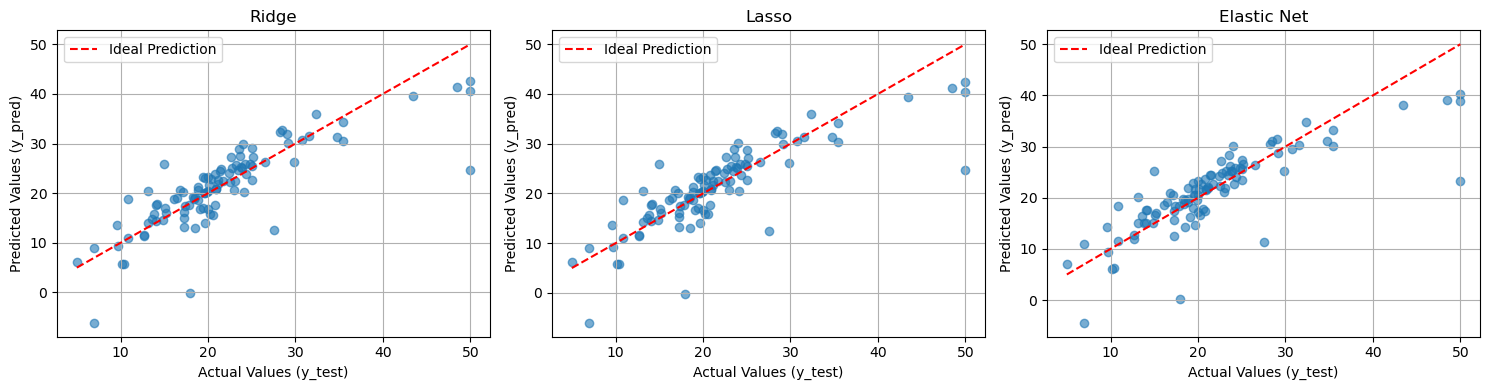

In [82]:
plt.figure(figsize=(15, 4))

predictions = [y_pred_ridge, y_pred_lasso, y_pred_elastic]
models = ["Ridge", "Lasso", "Elastic Net"]

for i in range(3):
    plt.subplot(1, 3, i+1)
    plt.scatter(y_test, predictions[i], alpha=0.6)
    plt.plot([min(y_test), max(y_test)],[min(y_test), max(y_test)],'r--',label="Ideal Prediction")
    plt.xlabel("Actual Values (y_test)")
    plt.ylabel("Predicted Values (y_pred)")
    plt.title(models[i])
    plt.legend()
    plt.grid()

plt.tight_layout()
plt.show()

In [84]:
comparison = pd.DataFrame({
    "Model": ["Ridge", "Lasso", "Elastic Net"],
    "Alpha": [best_alpha_ridge,best_alpha_lasso,best_alpha_elastic],
    "l1_ratio": ["-", "-", best_l1_ratio],
    "Testing MSE": [ mean_squared_error(y_test, y_pred_ridge),mean_squared_error(y_test, y_pred_lasso),mean_squared_error(y_test, y_pred_elastic)],
    "R2 Score": [r2_score(y_test, y_pred_ridge),r2_score(y_test, y_pred_lasso),r2_score(y_test, y_pred_elastic)]
})

print(comparison)

         Model  Alpha l1_ratio  Testing MSE  R2 Score
0        Ridge   0.01        -    24.291337  0.668757
1        Lasso   0.01        -    24.333499  0.668182
2  Elastic Net   0.10     0.01    24.885877  0.660649


In [86]:
best_model = comparison.loc[comparison["Testing MSE"].idxmin()]

print("Best Model:", best_model["Model"])
print("Minimum Testing MSE:", best_model["Testing MSE"])

Best Model: Ridge
Minimum Testing MSE: 24.291336890171532


In [88]:
#hyper parameter tuning for elastic both parametrs
# Elastic Net hyperparameter tuning

alpha_values = [0.01, 0.02, 0.05, 0.1, 0.11, 0.5, 0.9, 1, 2]
l1_ratios = [0.01, 0.1, 0.5, 0.7, 1]

elastic_results = []

for alpha in alpha_values:
    for ratio in l1_ratios:
        model_elastic = ElasticNet(alpha=alpha,l1_ratio=ratio,max_iter=10000)
        model_elastic.fit(X_train_scaled, y_train)
        y_train_pred = model_elastic.predict(X_train_scaled)
        y_test_pred = model_elastic.predict(X_test_scaled)

        train_mse = mean_squared_error(y_train, y_train_pred)
        test_mse = mean_squared_error(y_test, y_test_pred)
        r2 = r2_score(y_test, y_test_pred)

        elastic_results.append([alpha, ratio, train_mse, test_mse, r2])

elastic_df = pd.DataFrame(elastic_results,columns=["Alpha", "l1_ratio", "Training MSE","Testing MSE", "R2 Score"])
print(elastic_df.to_string(index=False))

 Alpha  l1_ratio  Training MSE  Testing MSE  R2 Score
  0.01      0.01     21.660018    24.377938  0.667576
  0.01      0.10     21.658709    24.374262  0.667626
  0.01      0.50     21.653507    24.357532  0.667854
  0.01      0.70     21.651308    24.348540  0.667976
  0.01      1.00     21.648543    24.333499  0.668182
  0.02      0.01     21.704000    24.459377  0.666465
  0.02      0.10     21.700213    24.454689  0.666529
  0.02      0.50     21.684982    24.432700  0.666829
  0.02      0.70     21.678349    24.419054  0.667015
  0.02      1.00     21.669830    24.394265  0.667353
  0.05      0.01     21.904443    24.659536  0.663736
  0.05      0.10     21.889568    24.675612  0.663516
  0.05      0.50     21.835173    24.713067  0.663006
  0.05      0.70     21.812584    24.723544  0.662863
  0.05      1.00     21.784804    24.732823  0.662736
  0.10      0.01     22.321112    24.885877  0.660649
  0.10      0.10     22.291252    24.936040  0.659965
  0.10      0.50     22.1815

In [90]:
print(elastic_df[elastic_df["Alpha"] == 0.1][["Alpha", "l1_ratio", "Testing MSE"]].to_string(index=False))

 Alpha  l1_ratio  Testing MSE
   0.1      0.01    24.885877
   0.1      0.10    24.936040
   0.1      0.50    25.203553
   0.1      0.70    25.351668
   0.1      1.00    25.656739


In [94]:
#optimum huper parameter
best_elastic = elastic_df.loc[elastic_df["Testing MSE"].idxmin()]
best_alpha_elastic = best_elastic["Alpha"]
best_l1_ratio = best_elastic["l1_ratio"]

print("Best Alpha:", best_alpha_elastic)
print("Best l1_ratio:", best_l1_ratio)
print("Minimum Testing MSE:", best_elastic["Testing MSE"])
print("R2 Score:", best_elastic["R2 Score"])

Best Alpha: 0.01
Best l1_ratio: 1.0
Minimum Testing MSE: 24.333499160616338
R2 Score: 0.6681815922762606


In [96]:
# Select optimum alpha for Ridge and Lasso
best_alpha_ridge = ridge_df.loc[ ridge_df["Testing MSE"].idxmin(), "Alpha"]
best_alpha_lasso = lasso_df.loc[lasso_df["Testing MSE"].idxmin(), "Alpha"]

print("Ridge Alpha:", best_alpha_ridge)
print("Lasso Alpha:", best_alpha_lasso)
print("Elastic Alpha:", best_alpha_elastic)
print("Elastic l1_ratio:", best_l1_ratio)

Ridge Alpha: 0.01
Lasso Alpha: 0.01
Elastic Alpha: 0.01
Elastic l1_ratio: 1.0


In [98]:
# Ridge
model_ridge = Ridge(alpha=best_alpha_ridge)
model_ridge.fit(X_train_scaled, y_train)
y_pred_ridge = model_ridge.predict(X_test_scaled)

# Lasso
model_lasso = Lasso(alpha=best_alpha_lasso, max_iter=10000)
model_lasso.fit(X_train_scaled, y_train)
y_pred_lasso = model_lasso.predict(X_test_scaled)

# Elastic Net
model_elastic = ElasticNet(alpha=best_alpha_elastic,l1_ratio=best_l1_ratio,max_iter=10000)

model_elastic.fit(X_train_scaled, y_train)
y_pred_elastic = model_elastic.predict(X_test_scaled)

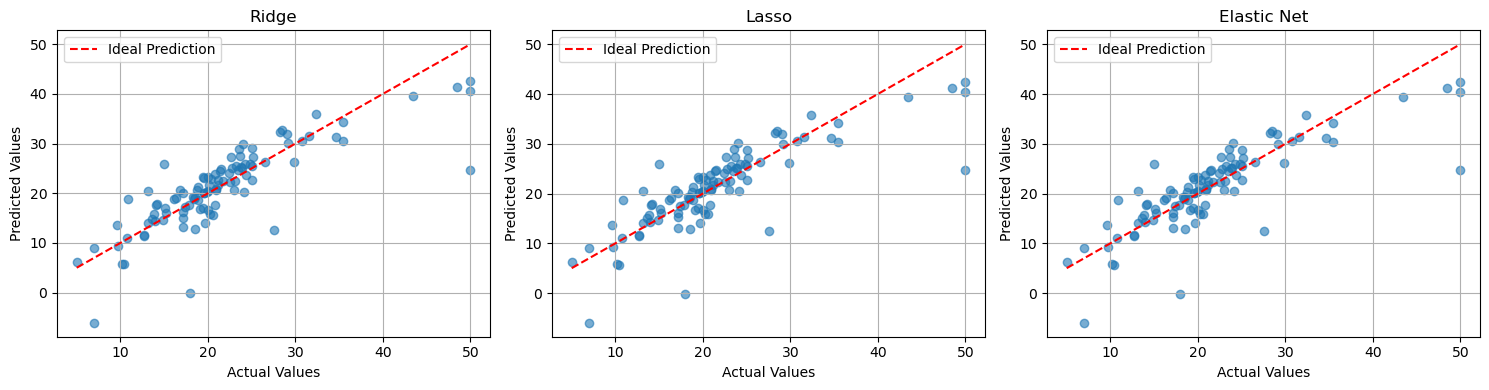

In [100]:
plt.figure(figsize=(15, 4))

predictions = [y_pred_ridge, y_pred_lasso, y_pred_elastic]
model_names = ["Ridge", "Lasso", "Elastic Net"]

for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.scatter(y_test, predictions[i], alpha=0.6)

    plt.plot([min(y_test), max(y_test)],[min(y_test), max(y_test)],"r--", label="Ideal Prediction")
    plt.xlabel("Actual Values")
    plt.ylabel("Predicted Values")
    plt.title(model_names[i])
    plt.legend()
    plt.grid()

plt.tight_layout()
plt.show()